In [1]:
import pandas as pd
import pickle
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
import optuna
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    precision_recall_curve,
    auc,
    ConfusionMatrixDisplay
)


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ============================================================
# CONFIGURAÇÃO DO BALANCEAMENTO
# ============================================================

BALANCEAMENTO = "oversampling"

# Opções:
# "undersampling"
# "oversampling"
# "smote"

In [3]:
# ============================================================
# 1. PARÂMETROS DO MLP
# ============================================================



# ============================================================
# PARÂMETROS FIXOS
# ============================================================

FIXED_PARAMS = {
    "activation": "relu",
    "solver": "adam",
    "early_stopping": False,
    "random_state": 42
}


# ============================================================
# CONFIGURAÇÃO DO OPTUNA
# ============================================================

# Configuracao do Optuna para busca de hiperparametros
# com foco em F1 e Oversampling (Hold-out Temporal sem folds).

n_trials = 50
study_seed = 42
threshold_grid_tune = np.arange(0.05, 0.86, 0.01)


In [4]:

# ============================================================
# FUNÇÃO DE BALANCEAMENTO
# ============================================================

def balancear_dados(X, y, tecnica):
    if tecnica == "undersampling":
        balanceador = RandomUnderSampler(
            random_state=42
        )

    elif tecnica == "oversampling":
        balanceador = RandomOverSampler(
            random_state=42
        )

    elif tecnica == "smote":
        balanceador = SMOTE(
            random_state=42,
            k_neighbors=5
        )

    else:
        raise ValueError(
            f"Técnica inválida: {tecnica}"
        )

    return balanceador.fit_resample(X, y)


In [5]:
# ============================================================
# 2. CARREGAMENTO DO DATASET
# ============================================================

arquivo = "C:/Users/gques/Documents/SPTECH_CODIGOS/ultimo-ano/tcc/backend/tabela_final/table_orders_holidays_ecommerce_events.csv"


df = pd.read_csv(arquivo)

In [6]:


target_col = "delivered_on_time"
if target_col not in df.columns:
    raise ValueError(f"A coluna alvo '{target_col}' nao foi encontrada no CSV.")

# =====================================================================
# 1. ENGENHARIA DO SLA (Prazo da Transportadora - LAST MILE)
# =====================================================================
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'], utc=True)
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'], utc=True)
df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], utc=True)

# Quantos dias a transportadora tem para entregar apos pegar o pacote?
df['prazo_transportadora_dias'] = (df['order_estimated_delivery_date'] - df['order_delivered_carrier_date']).dt.days

# Remover os casos onde a transportadora nunca pegou o pacote para evitar NaN no treino
df = df.dropna(subset=['prazo_transportadora_dias']).copy()

# Extraindo o mes da compra (sazonalidade - Black Friday, Natal)
df['carrier_month'] = df['order_delivered_carrier_date'].dt.month

# =====================================================================
# 1b. FEATURES DE INTERAÇÃO (Adicionadas para aumentar o sinal)
# =====================================================================
df['prazo_por_km'] = df['prazo_transportadora_dias'] / (df['distance_km'] + 1)
df['frete_por_kg'] = df['freight_value'] / (df['product_weight_g'] / 1000 + 0.1)
df['densidade_produto'] = df['product_weight_g'] / (df['volume_cm3'] + 1)

# =====================================================================
# 2. ORDENAÇÃO CRONOLÓGICA (Baseada no momento da coleta)
# =====================================================================
df = df.sort_values('order_delivered_carrier_date').reset_index(drop=True)

# Divide em treino/teste com split temporal (Passado treina, Futuro testa).
# Treino: ate Junho de 2018 | Teste: Julho de 2018 em diante.
date_col = df['order_delivered_carrier_date'].copy()
split_date = pd.to_datetime("2018-07-01", utc=True)

leakage_candidates = [
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "shipping_delay_hours",
    "delivery_time_days",
    "review_score",
]
leakage_cols = [c for c in leakage_candidates if c in df.columns]

# Separa previsores e alvo.
feature_cols = [c for c in df.columns if c != target_col and c not in leakage_cols]
X = df[feature_cols].copy()
# Inverte o alvo: atraso = 1, no prazo = 0.
y = (~df[target_col].astype(bool)).astype(int).copy()

colunas_remover = [
    "order_purchase_timestamp",
    "order_approved_at",
    "interval_code_delivered_carrier",
    "interval_code_delivered_customer",
    "order_estimated_delivery_date", # Ja usamos
    "shipping_limit_date",
    "delivered_on_time",
    "review_score",
    # "had_ecommerce_event_14_days_ago",
    
    # --- FEATURES REDUNDANTES / BAIXA INFLUENCIA REMOVIDAS ---
    "is_holiday_in_7_days",
    "is_holiday_in_14_days",
    "had_holiday_7_days_ago",
    "had_holiday_14_days_ago",
    "holiday_at_purchase",
    "is_weekend",
    "customer_city",
    "seller_city",
    "category_name"
]

X = X.drop(columns=colunas_remover, errors='ignore')

train_mask = date_col < split_date
test_mask = date_col >= split_date

X_train = X[train_mask].copy()
y_train = y[train_mask].copy()
X_test = X[test_mask].copy()
y_test = y[test_mask].copy()


# ============================================================
# 10. HOLD-OUT TEMPORAL PARA BUSCA DE HIPERPARÂMETROS
# ============================================================

# Data de corte entre treinamento e validação.
# Treinamento: até abril/2018.
# Validação: maio e junho/2018.

val_split_date = pd.to_datetime("2018-05-01", utc=True)

carrier_train_dates = pd.to_datetime(
    df.loc[X_train.index, "order_delivered_carrier_date"],
    utc=True
)

customer_train_dates = pd.to_datetime(
    df.loc[X_train.index, "order_delivered_customer_date"],
    utc=True
)

# Identificação do treinamento e validação.
tr_mask_tune = (
    (carrier_train_dates < val_split_date) &
    (customer_train_dates < val_split_date)
)

va_mask_tune = (
    carrier_train_dates >= val_split_date
)

# Identificação dos registros que serão expurgados.
n_expurgados_val = int(
    (
        (carrier_train_dates < val_split_date) &
        (customer_train_dates >= val_split_date)
    ).sum()
)

# Remove os registros que atravessam a fronteira temporal.
train_clean_mask = tr_mask_tune | va_mask_tune

X_train = X_train.loc[train_clean_mask].copy()
y_train = y_train.loc[train_clean_mask].copy()

carrier_train_dates = carrier_train_dates.loc[train_clean_mask]
customer_train_dates = customer_train_dates.loc[train_clean_mask]

# Índices dos conjuntos.
tr_idx = np.where(
    (carrier_train_dates < val_split_date).values
)[0]

va_idx = np.where(
    (carrier_train_dates >= val_split_date).values
)[0]

# Separação dos conjuntos.
X_treino_busca = X_train.iloc[tr_idx].copy()
y_treino_busca = y_train.iloc[tr_idx].copy()

X_validacao = X_train.iloc[va_idx].copy()
y_validacao = y_train.iloc[va_idx].copy()

# Normalização sem vazamento de dados.
scaler_busca = StandardScaler()

X_treino_busca = pd.DataFrame(
    scaler_busca.fit_transform(X_treino_busca),
    columns=X_train.columns,
    index=X_treino_busca.index
)

X_validacao = pd.DataFrame(
    scaler_busca.transform(X_validacao),
    columns=X_train.columns,
    index=X_validacao.index
)

# Estatísticas.
qtd_tr_tune = len(X_treino_busca)
qtd_va_tune = len(X_validacao)
qtd_treino = len(X_train)
qtd_teste = len(X_test)

total_linhas = len(X)

pos_count = int((y_train == 1).sum())
atrasos_tr_tune = int((y_treino_busca == 1).sum())
atrasos_va_tune = int((y_validacao == 1).sum())

carrier_test_dates = pd.to_datetime(
    df.loc[X_test.index, "order_delivered_carrier_date"],
    utc=True
)

print("=" * 100)
print("DISTRIBUIÇÃO DOS DADOS - HOLD-OUT TEMPORAL")
print("=" * 100)

print(f"Total de registros: {total_linhas:,}\n")

print("1. SEPARAÇÃO GERAL")
print("-" * 100)

print(f"Treino completo: {qtd_treino:,}")
print(
    f"Atrasos: {pos_count:,} "
    f"({pos_count/qtd_treino:.2%})"
)

print(f"Teste independente: {qtd_teste:,}")
print(
    f"Atrasos: {(y_test == 1).sum():,} "
    f"({(y_test == 1).mean():.2%})\n"
)

print("2. HOLD-OUT TEMPORAL")
print("-" * 100)

print(f"Treino de tuning: {qtd_tr_tune:,}")
print(
    f"Período: {carrier_train_dates.iloc[tr_idx].min():%d/%m/%Y} "
    f"a {carrier_train_dates.iloc[tr_idx].max():%d/%m/%Y}"
)
print(
    f"Atrasos: {atrasos_tr_tune:,} "
    f"({atrasos_tr_tune/qtd_tr_tune:.2%})"
)

print(f"Pedidos expurgados: {n_expurgados_val:,}\n")

print(f"Validação: {qtd_va_tune:,}")
print(
    f"Período: {carrier_train_dates.iloc[va_idx].min():%d/%m/%Y} "
    f"a {carrier_train_dates.iloc[va_idx].max():%d/%m/%Y}"
)
print(
    f"Atrasos: {atrasos_va_tune:,} "
    f"({atrasos_va_tune/qtd_va_tune:.2%})"
)

print("=" * 100)

X_test.head()


DISTRIBUIÇÃO DOS DADOS - HOLD-OUT TEMPORAL
Total de registros: 34,283

1. SEPARAÇÃO GERAL
----------------------------------------------------------------------------------------------------
Treino completo: 29,098
Atrasos: 1,367 (4.70%)
Teste independente: 5,185
Atrasos: 521 (10.05%)

2. HOLD-OUT TEMPORAL
----------------------------------------------------------------------------------------------------
Treino de tuning: 23,988
Período: 08/10/2016 a 27/04/2018
Atrasos: 1,203 (5.02%)
Pedidos expurgados: 0

Validação: 5,110
Período: 02/05/2018 a 29/06/2018
Atrasos: 164 (3.21%)


,carrier_month,holiday_at_carrier,days_since_last_holiday,days_until_next_holiday,ecommerce_event_at_carrier,days_since_last_ecommerce_event,days_until_next_ecommerce_event,is_ecommerce_event_in_7_days,is_ecommerce_event_in_14_days,had_ecommerce_event_7_days_ago,...,distance_km,same_city,carrier_available_days,delivery_time_per_km,freight_per_kg,product_density,prazo_transportadora_dias,prazo_por_km,frete_por_kg,densidade_produto
29098,7,0,32,7,0,20,41,0,0,0,...,65.455,0,17,0.259720,65.350000,0.050505,16,0.240764,43.566667,0.050492
29099,7,0,32,7,0,20,41,0,0,0,...,410.895,0,17,0.041373,5.855319,0.220699,16,0.038845,5.616327,0.220678
29100,7,0,32,7,0,20,41,0,0,0,...,284.356,0,21,0.073851,29.411765,0.140110,20,0.070088,24.150268,0.140067
29101,7,0,32,7,0,20,41,0,0,0,...,220.486,0,18,0.081638,52.000000,0.390625,17,0.076754,37.142857,0.390016
29102,7,0,32,7,0,20,41,0,0,0,...,114.112,0,11,0.096397,5.431165,0.094160,10,0.086872,5.271659,0.094157


In [7]:


# ============================================================
# 11. BUSCA DE HIPERPARÂMETROS E THRESHOLD COM OPTUNA
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # HIPERPARÂMETROS DA MLP
    # --------------------------------------------------------

    arquitetura = trial.suggest_categorical(
        "hidden_layer_sizes",
        [
            "32,16",
            "64,32",
            "64,32,16"
        ]
    )

    hidden_layer_sizes = tuple(
        int(x) for x in arquitetura.split(",")
    )

    learning_rate_init = trial.suggest_categorical(
        "learning_rate_init",
        [0.0001, 0.0003, 0.001]
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [32, 64, 128]
    )

    alpha = trial.suggest_categorical(
        "alpha",
        [0.0001, 0.001, 0.01]
    )

    max_iter = trial.suggest_categorical(
        "max_iter",
        [50, 100]
    )

    # --------------------------------------------------------
    # TREINAMENTO
    # --------------------------------------------------------

    parametros = {
        "hidden_layer_sizes": hidden_layer_sizes,
        "learning_rate_init": learning_rate_init,
        "batch_size": batch_size,
        "alpha": alpha,
        "max_iter": max_iter
    }

    mlp_teste = MLPClassifier(
        **FIXED_PARAMS,
        **parametros
    )

    # Balanceamento somente no conjunto de treinamento.
    X_treino_balanceado, y_treino_balanceado = balancear_dados(
        X_treino_busca,
        y_treino_busca,
        BALANCEAMENTO
    )

    mlp_teste.fit(
        X_treino_balanceado,
        y_treino_balanceado
    )

    # --------------------------------------------------------
    # PREDIÇÃO NA VALIDAÇÃO
    # --------------------------------------------------------

    y_prob_validacao = mlp_teste.predict_proba(
        X_validacao
    )[:, 1]

    # --------------------------------------------------------
    # BUSCA DO MELHOR THRESHOLD PELO F1
    # --------------------------------------------------------

    melhor_f1 = -1
    melhor_threshold = 0.50
    melhor_y_pred = None

    for threshold in threshold_grid_tune:

        y_pred_validacao = (
            y_prob_validacao >= threshold
        ).astype(int)

        f1_atual = f1_score(
            y_validacao,
            y_pred_validacao,
            pos_label=1,
            zero_division=0
        )

        if f1_atual > melhor_f1:

            melhor_f1 = f1_atual
            melhor_threshold = float(threshold)
            melhor_y_pred = y_pred_validacao.copy()

    # --------------------------------------------------------
    # MÉTRICAS DO MELHOR THRESHOLD
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_validacao,
        melhor_y_pred
    )

    precision = precision_score(
        y_validacao,
        melhor_y_pred,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_validacao,
        melhor_y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_validacao,
        melhor_y_pred,
        pos_label=1,
        zero_division=0
    )

    f2 = fbeta_score(
        y_validacao,
        melhor_y_pred,
        beta=2,
        pos_label=1,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_validacao,
        y_prob_validacao
    )

    precision_pr, recall_pr, _ = precision_recall_curve(
        y_validacao,
        y_prob_validacao,
        pos_label=1
    )

    pr_auc = auc(
        recall_pr,
        precision_pr
    )

    # --------------------------------------------------------
    # SALVA MÉTRICAS DA TENTATIVA
    # --------------------------------------------------------

    trial.set_user_attr("threshold", melhor_threshold)
    trial.set_user_attr("accuracy", accuracy)
    trial.set_user_attr("precision", precision)
    trial.set_user_attr("recall", recall)
    trial.set_user_attr("f1", f1)
    trial.set_user_attr("f2", f2)
    trial.set_user_attr("roc_auc", roc_auc)
    trial.set_user_attr("pr_auc", pr_auc)
    trial.set_user_attr(
        "epocas_executadas",
        mlp_teste.n_iter_
    )

    print(
        f"\nTentativa {trial.number + 1}/{n_trials} | "
        f"Balanceamento: {BALANCEAMENTO} | "
        f"Threshold: {melhor_threshold:.2f} | "
        f"F1: {f1:.4f} | "
        f"Recall: {recall:.4f} | "
        f"Precision: {precision:.4f}"
    )

    # O Optuna buscará maximizar o F1.
    return f1


# ============================================================
# 11.1 EXECUÇÃO DO OPTUNA
# ============================================================

print("\n" + "=" * 70)
print("INICIANDO OTIMIZAÇÃO COM OPTUNA")
print("=" * 70)

sampler = optuna.samplers.TPESampler(
    seed=study_seed
)

study = optuna.create_study(
    direction="maximize",
    sampler=sampler
)

study.optimize(
    objective,
    n_trials=n_trials
)



# ============================================================
# 11.2 RESULTADOS DAS 50 TENTATIVAS - CONFIGURACOES UNICAS
# ============================================================

resultados = []

for trial in study.trials:

    if trial.state == optuna.trial.TrialState.COMPLETE:

        resultado = {
            **trial.params,
            **trial.user_attrs
        }

        resultados.append(resultado)


resultados_df = pd.DataFrame(resultados)

# Converte a arquitetura armazenada como texto
# novamente para tupla de inteiros.

resultados_df["hidden_layer_sizes"] = (
    resultados_df["hidden_layer_sizes"]
    .apply(
        lambda x: tuple(
            int(valor) for valor in x.split(",")
        )
    )
)

# Remove configurações repetidas considerando os hiperparâmetros.
# O threshold não é considerado, pois é selecionado internamente
# para cada configuração com base no F1 da validação.

resultados_df = resultados_df.drop_duplicates(
    subset=[
        "hidden_layer_sizes",
        "learning_rate_init",
        "batch_size",
        "alpha",
        "max_iter"
    ]
)

# Ranking:
# 1. Maior F1
# 2. Maior PR-AUC
# 3. Maior Recall

resultados_df = resultados_df.sort_values(
    by=["f1", "pr_auc", "recall"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("MELHORES CONFIGURAÇÕES ÚNICAS")
print("=" * 70)

display(
    resultados_df.head(10)
)



# ============================================================
# 11.3 MELHOR CONFIGURAÇÃO ENCONTRADA
# ============================================================

melhor_trial = study.best_trial

BEST_PARAMS = {
    "hidden_layer_sizes": tuple(
        int(x)
        for x in melhor_trial.params[
            "hidden_layer_sizes"
        ].split(",")
    ),

    "learning_rate_init": melhor_trial.params[
        "learning_rate_init"
    ],

    "batch_size": int(
        melhor_trial.params["batch_size"]
    ),

    "alpha": melhor_trial.params["alpha"],

    "max_iter": int(
        melhor_trial.params["max_iter"]
    )
}

# Threshold escolhido pela busca em grade.
THRESHOLD = float(
    melhor_trial.user_attrs["threshold"]
)

MLP_PARAMS = {
    **FIXED_PARAMS,
    **BEST_PARAMS
}


print("\n" + "=" * 70)
print("MELHOR CONFIGURAÇÃO ENCONTRADA")
print("=" * 70)

print(f"Balanceamento:     {BALANCEAMENTO}")
print(f"Arquitetura:       {BEST_PARAMS['hidden_layer_sizes']}")
print(f"Learning rate:     {BEST_PARAMS['learning_rate_init']}")
print(f"Batch size:        {BEST_PARAMS['batch_size']}")
print(f"Alpha:             {BEST_PARAMS['alpha']}")
print(f"Max iter:          {BEST_PARAMS['max_iter']}")
print(f"Threshold:         {THRESHOLD:.2f}")

print("\nParâmetros fixos:")
print(f"Activation:        {FIXED_PARAMS['activation']}")
print(f"Solver:            {FIXED_PARAMS['solver']}")

print("\nResultado na validação:")
print(
    f"Accuracy:           {melhor_trial.user_attrs['accuracy']:.4f}"
)
print(
    f"Precision:          {melhor_trial.user_attrs['precision']:.4f}"
)
print(
    f"Recall:             {melhor_trial.user_attrs['recall']:.4f}"
)
print(
    f"F1:                 {melhor_trial.user_attrs['f1']:.4f}"
)
print(
    f"F2:                 {melhor_trial.user_attrs['f2']:.4f}"
)
print(
    f"ROC-AUC:            {melhor_trial.user_attrs['roc_auc']:.4f}"
)
print(
    f"PR-AUC:             {melhor_trial.user_attrs['pr_auc']:.4f}"
)




# ============================================================
# 11.3 TREINAMENTO FINAL COM A MELHOR CONFIGURAÇÃO
# ============================================================

print("\n" + "=" * 70)
print("TREINAMENTO FINAL")
print("=" * 70)

# Novo scaler ajustado com todo o treinamento.
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Treinamento final.

# ============================================================
# BALANCEAMENTO DO TREINAMENTO FINAL
# ============================================================

X_train_balanceado, y_train_balanceado = balancear_dados(
    X_train_scaled,
    y_train,
    BALANCEAMENTO
)

# ============================================================
# TREINAMENTO FINAL
# ============================================================

mlp = MLPClassifier(
    **MLP_PARAMS
)

mlp.fit(
    X_train_balanceado,
    y_train_balanceado
)

print(
    f"Épocas executadas no modelo final: {mlp.n_iter_}"
)

print(f"Técnica de balanceamento: {BALANCEAMENTO}")
print(f"Threshold selecionado: {THRESHOLD:.2f}")


print(
    f"Épocas executadas no modelo final: {mlp.n_iter_}"
)


# ============================================================
# 11.4 SALVAMENTO DO MODELO FINAL
# ============================================================

# O modelo recebe 26 variáveis numéricas, mas a API recebe os campos brutos
# do formulário/CSV. Por isso, o artefato precisa carregar também os mapas
# de target encoding criados SOMENTE com o conjunto de treino.

raw_columns = [
    "purchase_date",
    "purchase_time",
    "carrier_datetime",
    "estimated_delivery_datetime",
    "price",
    "freight_value",
    "product_weight_g",
    "height_cm",
    "width_cm",
    "length_cm",
    "distance_km",
    "same_city"
]

modelo = {
    # Objetos necessários para a inferência
    "model": mlp,
    "scaler": scaler,
    "features": X_train.columns.tolist(),
    "feature_names": X_train.columns.tolist(),
    "threshold": float(THRESHOLD),
    "params": MLP_PARAMS,

    # Dados necessários para repetir o pré-processamento da API
    "raw_columns": raw_columns,
    "inference_moment": "carrier_collection",
    "ecommerce_events": [
        "mothers_day", "fathers_day", "children_day",
        "black_friday", "cyber_monday", "christmas",
    ],

    # Contrato do artefato consumido pela API
    "schema_version": 3,
    "model_type": "MLPClassifier",
    "model_name": "MLP (Rede Neural)",
}


caminho_modelo = Path.cwd() / (
    f"modelo_mlp_{BALANCEAMENTO}.pkl"
)


with open(
    caminho_modelo,
    "wb"
) as arquivo:

    pickle.dump(
        modelo,
        arquivo,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print(
    f"\nModelo final salvo com sucesso em: "
    f"{caminho_modelo}"
)
print(f"Variáveis do modelo: {len(modelo['features'])}")
print(f"Limiar de atraso: {modelo['threshold']:.2f}")


# ============================================================
# 11.5 GRÁFICOS DE TREINAMENTO E VALIDAÇÃO
# ============================================================

# Recria a MLP utilizando a melhor configuração encontrada
# pelo Optuna, para acompanhar as métricas por época.

# Mantém o estado aleatório entre as chamadas de partial_fit.
params_graficos = MLP_PARAMS.copy()

params_graficos["random_state"] = np.random.RandomState(
    FIXED_PARAMS["random_state"]
)

mlp_graficos = MLPClassifier(**params_graficos)

# Armazenamento das métricas por época.
perda_treinamento = []
acuracia_validacao = []

# Critérios de convergência utilizados pelo MLP.
melhor_perda = np.inf
epocas_sem_melhoria = 0

tol = MLP_PARAMS.get("tol", 1e-4)
n_iter_no_change = MLP_PARAMS.get("n_iter_no_change", 10)

# Cada chamada de partial_fit executa uma época.
for epoca in range(1, MLP_PARAMS["max_iter"] + 1):

    if epoca == 1:

        mlp_graficos.partial_fit(
            X_treino_busca,
            y_treino_busca,
            classes=np.array([0, 1])
        )

    else:

        mlp_graficos.partial_fit(
            X_treino_busca,
            y_treino_busca
        )

    # --------------------------------------------------------
    # PERDA DO TREINAMENTO
    # --------------------------------------------------------

    perda_atual = float(mlp_graficos.loss_)

    perda_treinamento.append(perda_atual)

    # --------------------------------------------------------
    # ACURÁCIA NA VALIDAÇÃO TEMPORAL
    # --------------------------------------------------------

    y_prob_validacao_epoca = mlp_graficos.predict_proba(
        X_validacao
    )[:, 1]

    y_pred_validacao_epoca = (
        y_prob_validacao_epoca >= THRESHOLD
    ).astype(int)

    acuracia_atual = accuracy_score(
        y_validacao,
        y_pred_validacao_epoca
    )

    acuracia_validacao.append(acuracia_atual)

    # --------------------------------------------------------
    # CRITÉRIO DE CONVERGÊNCIA
    # --------------------------------------------------------

    if perda_atual < melhor_perda - tol:

        melhor_perda = perda_atual
        epocas_sem_melhoria = 0

    else:

        epocas_sem_melhoria += 1

    if epocas_sem_melhoria > n_iter_no_change:
        break


# Quantidade efetiva de épocas executadas.
epocas = np.arange(
    1,
    len(perda_treinamento) + 1
)


# ============================================================
# CONSTRUÇÃO DOS GRÁFICOS
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# GRÁFICO 1 - PERDA DE TREINAMENTO
# ------------------------------------------------------------

axes[0].plot(
    epocas,
    perda_treinamento,
    label="Perda de treinamento (Log-loss)",
    linewidth=2
)

axes[0].set_title(
    "Perda de treinamento por época"
)

axes[0].set_xlabel("Épocas")

axes[0].set_ylabel(
    "Log-loss (entropia cruzada + regularização L2)"
)

axes[0].grid(True, alpha=0.3)
axes[0].legend()


# ------------------------------------------------------------
# GRÁFICO 2 - ACURÁCIA DE VALIDAÇÃO
# ------------------------------------------------------------

axes[1].plot(
    epocas,
    acuracia_validacao,
    label=f"Acurácia de validação (limiar {THRESHOLD:.2f})",
    linewidth=2
)

axes[1].set_title(
    "Acurácia de validação por época"
)

axes[1].set_xlabel("Épocas")

axes[1].set_ylabel("Acurácia")

axes[1].set_ylim(0, 1)

axes[1].grid(True, alpha=0.3)
axes[1].legend()


# ============================================================
# EXPORTAÇÃO DOS GRÁFICOS
# ============================================================

fig.suptitle(
    "Curvas de treinamento e validação da rede MLP",
    fontsize=13
)

fig.tight_layout()

caminho_grafico = (
    Path.cwd() / "mpl-v1-range-de-parametros_oversampling.png"
)

fig.savefig(
    caminho_grafico,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.close(fig)

print(
    f"\nGráficos exportados com sucesso: {caminho_grafico}"
)

[I 2026-11-15 13:49:04,393] A new study created in memory with name: no-name-d717f57b-f4e3-4ae7-9265-77e38cbe4acf



INICIANDO OTIMIZAÇÃO COM OPTUNA


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
[I 2026-11-15 13:49:20,094] Trial 0 finished with value: 0.2431865828092243 and parameters: {'hidden_layer_sizes': '64,32', 'learning_rate_init': 0.0001, 'batch_size': 64, 'alpha': 0.01, 'max_iter': 50}. Best is trial 0 with value: 0.2431865828092243.



Tentativa 1/50 | Balanceamento: oversampling | Threshold: 0.85 | F1: 0.2432 | Recall: 0.3537 | Precision: 0.1853


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
[I 2026-11-15 13:50:20,019] Trial 1 finished with value: 0.20249653259361997 and parameters: {'hidden_layer_sizes': '64,32,16', 'learning_rate_init': 0.0001, 'batch_size': 32, 'alpha': 0.01, 'max_iter': 100}. Best is trial 0 with value: 0.2431865828092243.



Tentativa 2/50 | Balanceamento: oversampling | Threshold: 0.60 | F1: 0.2025 | Recall: 0.4451 | Precision: 0.1311


... (96 outputs left out)

,hidden_layer_sizes,learning_rate_init,batch_size,alpha,max_iter,threshold,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,epocas_executadas
0,"(64, 32)",0.0001,128,0.0010,50,0.85,0.934834,0.203509,0.353659,0.258352,0.308183,0.798525,0.224735,50
1,"(64, 32)",0.0001,128,0.0100,50,0.85,0.935616,0.204301,0.347561,0.257336,0.304813,0.794209,0.218575,50
2,"(64, 32)",0.0001,128,0.0001,50,0.85,0.933855,0.200000,0.353659,0.255507,0.306554,0.798658,0.223433,50
3,"(32, 16)",0.0001,128,0.0010,50,0.85,0.946575,0.226131,0.274390,0.247934,0.263158,0.769946,0.173873,50
4,"(64, 32)",0.0001,64,0.0100,50,0.85,0.929354,0.185304,0.353659,0.243187,0.299278,0.775216,0.210533,50
5,"(64, 32)",0.0001,64,0.0010,50,0.85,0.925636,0.180473,0.371951,0.243028,0.306841,0.782613,0.220779,50
6,"(32, 16)",0.0001,64,0.0100,50,0.85,0.941292,0.206897,0.292683,0.242424,0.270270,0.766921,0.154028,50
7,"(32, 16)",0.0001,32,0.0010,50,0.85,0.932094,0.176678,0.304878,0.223714,0.266241,0.752982,0.142568,50
8,"(32, 16)",0.0001,32,0.0001,100,0.85,0.929159,0.172185,0.317073,0.223176,0.271399,0.741592,0.130967,100
9,"(64, 32)",0.0001,32,0.0010,50,0.85,0.916047,0.155844,0.365854,0.218579,0.288184,0.785643,0.199686,50



MELHOR CONFIGURAÇÃO ENCONTRADA
Balanceamento:     oversampling
Arquitetura:       (64, 32)
Learning rate:     0.0001
Batch size:        128
Alpha:             0.001
Max iter:          50
Threshold:         0.85

Parâmetros fixos:
Activation:        relu
Solver:            adam

Resultado na validação:
Accuracy:           0.9348
Precision:          0.2035
Recall:             0.3537
F1:                 0.2584
F2:                 0.3082
ROC-AUC:            0.7985
PR-AUC:             0.2247

TREINAMENTO FINAL


c:\Users\gques\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Épocas executadas no modelo final: 50
Técnica de balanceamento: oversampling
Threshold selecionado: 0.85
Épocas executadas no modelo final: 50

Modelo final salvo com sucesso em: c:\Users\gques\Documents\SPTECH_CODIGOS\ultimo-ano\tcc\backend\modelo\dl\modelo_mlp_oversampling.pkl
Variáveis do modelo: 27
Limiar de atraso: 0.85

Gráficos exportados com sucesso: c:\Users\gques\Documents\SPTECH_CODIGOS\ultimo-ano\tcc\backend\modelo\dl\mpl-v1-range-de-parametros_oversampling.png


# Gráfico 01
A curva de perda mostra o erro que o modelo apresenta durante o treinamento.

Curva decrescente: o modelo está aprendendo a ajustar seus pesos.

Curva estabilizada: o treinamento pode ter atingido um platô.

Curva crescente: pode indicar instabilidade ou dificuldades de otimização.

# Gráfico 02

A curva de validação mostra como o modelo classifica as amostras reservadas para validação durante o treinamento.

Acurácia crescente: o modelo está melhorando sua capacidade de classificação no conjunto de validação.

Acurácia estabilizada: pode indicar que o modelo deixou de apresentar melhorias.

Acurácia decrescente: pode indicar que o modelo está perdendo capacidade de generalização.

In [8]:
# ============================================================
# 12. PREDIÇÃO
# ============================================================

y_prob = mlp.predict_proba(
    X_test_scaled
)[:, 1]

y_pred = (
    y_prob >= THRESHOLD
).astype(int)

In [9]:
# ============================================================
# 13. MÉTRICAS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision_atraso = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall_atraso = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1_atraso = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f2_atraso = fbeta_score(
    y_test,
    y_pred,
    beta=2,
    pos_label=1,
    zero_division=0
)

roc_auc_atraso = roc_auc_score(
    y_test,
    y_prob
)

precision_pr, recall_pr, _ = precision_recall_curve(
    y_test,
    y_prob,
    pos_label=1
)

pr_auc_atraso = auc(
    recall_pr,
    precision_pr
)


RESULTADOS - MLP
Arquitetura: (64, 32)
Activation: relu
Solver: adam
Learning rate: 0.0001
Batch size: 128
Épocas máximas: 50
Limiar: 0.85

Quantidade de amostras:
Treino: 29098
Teste:  5185

Métricas:
Accuracy:        0.7545
Precision atraso: 0.2670
Recall atraso:    0.8273
F1 atraso:        0.4037
F2 atraso:        0.5827
ROC-AUC atraso:   0.8666
PR-AUC atraso:    0.4545

Como interpretar as métricas:
- Precision atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.
- Recall atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.
- F1 atraso: média harmônica entre precision e recall.
- F2 atraso: semelhante ao F1, mas dando mais peso ao recall.
- ROC-AUC atraso: capacidade do modelo de separar atrasos de não atrasos em diferentes limiares.
- PR-AUC atraso: desempenho no equilíbrio entre precision e recall para a classe atraso.


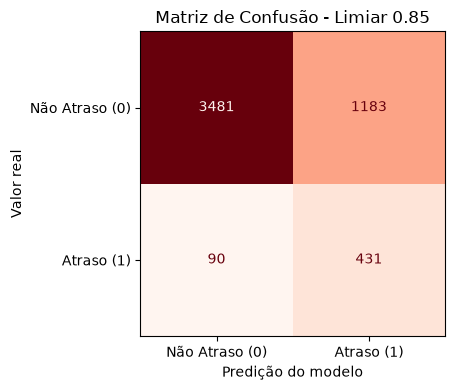


Relatório de classificação:
                precision    recall  f1-score   support

Não Atraso (0)       0.97      0.75      0.85      4664
    Atraso (1)       0.27      0.83      0.40       521

      accuracy                           0.75      5185
     macro avg       0.62      0.79      0.62      5185
  weighted avg       0.90      0.75      0.80      5185


Quantidade de épocas executadas:
50


In [10]:
# ============================================================
# 14. RESULTADOS
# ============================================================

print("\n" + "=" * 60)
print("RESULTADOS - MLP")
print("=" * 60)

print(f"Arquitetura: {MLP_PARAMS['hidden_layer_sizes']}")
print(f"Activation: {MLP_PARAMS['activation']}")
print(f"Solver: {MLP_PARAMS['solver']}")
print(f"Learning rate: {MLP_PARAMS['learning_rate_init']}")
print(f"Batch size: {MLP_PARAMS['batch_size']}")
print(f"Épocas máximas: {MLP_PARAMS['max_iter']}")
print(f"Limiar: {THRESHOLD:.2f}")

print("\nQuantidade de amostras:")
print(f"Treino: {len(X_train)}")
print(f"Teste:  {len(X_test)}")

print("\nMétricas:")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Precision atraso: {precision_atraso:.4f}")
print(f"Recall atraso:    {recall_atraso:.4f}")
print(f"F1 atraso:        {f1_atraso:.4f}")
print(f"F2 atraso:        {f2_atraso:.4f}")
print(f"ROC-AUC atraso:   {roc_auc_atraso:.4f}")
print(f"PR-AUC atraso:    {pr_auc_atraso:.4f}")

# ============================================================
# INTERPRETAÇÃO DAS MÉTRICAS
# ============================================================

print("\nComo interpretar as métricas:")
print("- Precision atraso: entre os pedidos previstos como atraso, quantos realmente atrasaram.")
print("- Recall atraso: entre os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar.")
print("- F1 atraso: média harmônica entre precision e recall.")
print("- F2 atraso: semelhante ao F1, mas dando mais peso ao recall.")
print("- ROC-AUC atraso: capacidade do modelo de separar atrasos de não atrasos em diferentes limiares.")
print("- PR-AUC atraso: desempenho no equilíbrio entre precision e recall para a classe atraso.")

# ============================================================
# MATRIZ DE CONFUSÃO
# ============================================================

fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Reds",
    ax=ax,
    colorbar=False,
    display_labels=[
        "Não Atraso (0)",
        "Atraso (1)"
    ]
)

ax.set_title(
    f"Matriz de Confusão - Limiar {THRESHOLD:.2f}"
)

ax.set_xlabel("Predição do modelo")
ax.set_ylabel("Valor real")

plt.tight_layout()
plt.show()

# ============================================================
# RELATÓRIO DE CLASSIFICAÇÃO
# ============================================================

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Não Atraso (0)",
            "Atraso (1)"
        ],
        zero_division=0
    )
)

print("\nQuantidade de épocas executadas:")
print(mlp.n_iter_)